In [1]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm
import math

os.chdir('/Users/eochoa/Documents/Research_Ambuj/ASD/Code/')

import pandas as pd
from utils import *
#from linear_utils import *
from logistic_utils import *
from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

from scipy.stats import multivariate_normal

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    #N = 10000
    #p = 10
    theta = scale*(2*np.random.rand(p)-1)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

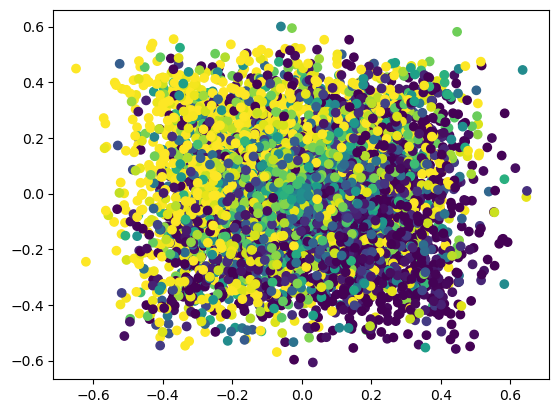

In [3]:
x, y, theta = gen_data(10000, p=10, scale=10)
plt.scatter(x[:,0],x[:,1], c=expit(x @ theta))

(array([ 69.,  71.,  77., 107., 161., 181., 103.,  93.,  69.,  69.]),
 array([0.1080186 , 0.18632053, 0.26462245, 0.34292438, 0.42122631,
        0.49952823, 0.57783016, 0.65613209, 0.73443402, 0.81273594,
        0.89103787]),
 <BarContainer object of 10 artists>)

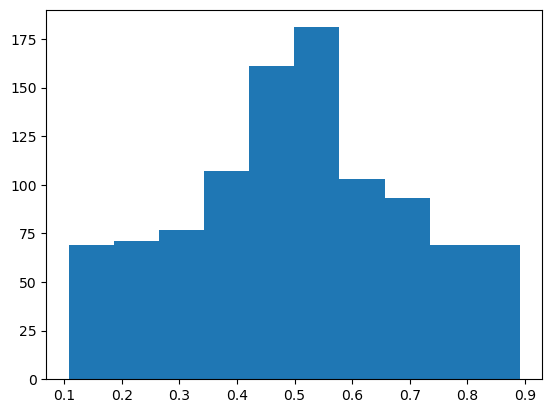

In [4]:
plt.hist(expit(x @ theta))

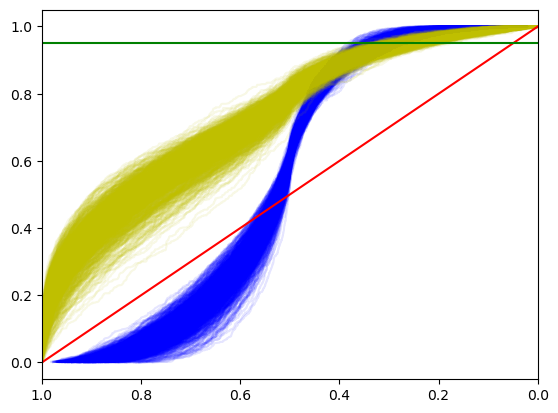

In [345]:
for i in range(1000):
    x, y, theta = gen_data(1000, p=10, scale=2)
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='b', alpha=.1)
    plt.xlim(1,0)
    
for i in range(1000):
    x, y, theta = gen_data(1000, p=10, scale=10)
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='y', alpha=.1)
    plt.xlim(1,0)
    
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')

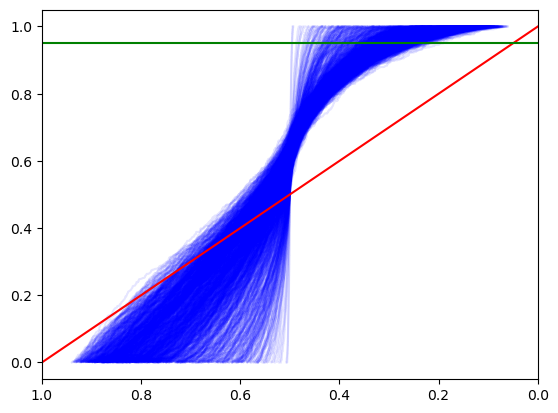

In [6]:
for i in range(1000):
    x, y, theta = gen_data(1000, scale=2)
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='b', alpha=.1)
    plt.xlim(1,0)
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')

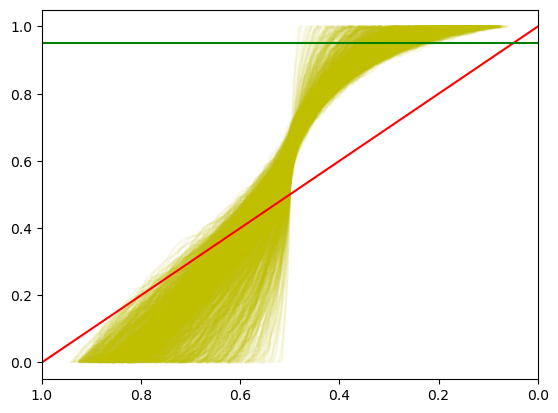

In [7]:
tau_list = []
prob_list = []
for i in range(1000):
    x, y, theta = gen_data(1000, scale=2)
    tau_list.append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    prob_list.append(np.sort(expit(x @ theta))[::-1][((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum()])
    
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='y', alpha=.1)
    plt.xlim(1,0)
    
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')
    

(array([ 14.,  30.,  61., 129., 169., 184., 146., 144.,  98.,  25.]),
 array([818. , 832.1, 846.2, 860.3, 874.4, 888.5, 902.6, 916.7, 930.8,
        944.9, 959. ]),
 <BarContainer object of 10 artists>)

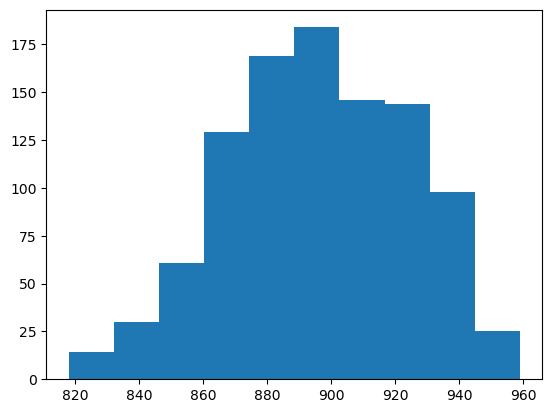

In [8]:
plt.hist(tau_list)

In [9]:
np.quantile(tau_list, .9)

933.1

100%|███████████████████████████████████████████| 30/30 [00:09<00:00,  3.13it/s]


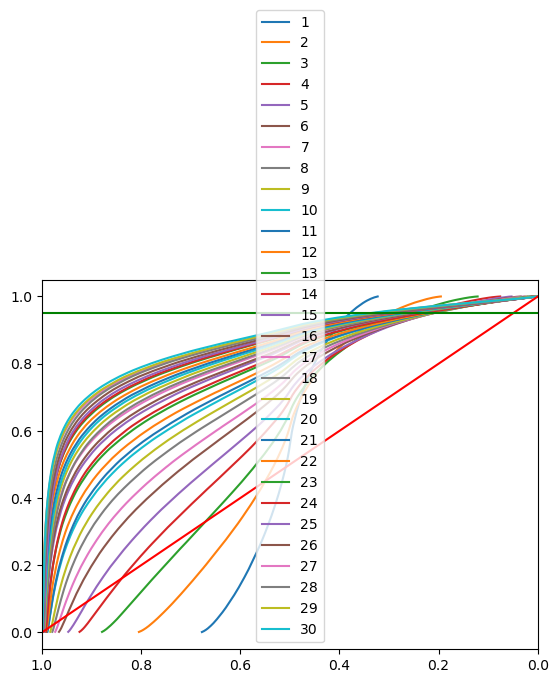

In [10]:
taus = []
probs = []
for j in trange(1,31):
    
    x_=[]
    y_=[]
    for i in range(1000):
        x, y, theta = gen_data(1000, scale=j)
        x_.append(np.sort(expit(x @ theta))[::-1])
        y_.append(y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum())
    
    taus.append(np.where((np.mean(y_,0)>.9).cumsum() ==1)[0][0])
    probs.append(np.mean(x_,0)[np.where((np.mean(y_,0)>.9).cumsum() ==1)][0])
    plt.plot(np.mean(x_,0),
            np.mean(y_,0), label=str(j))



plt.xlim(1,0)
plt.legend()
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')

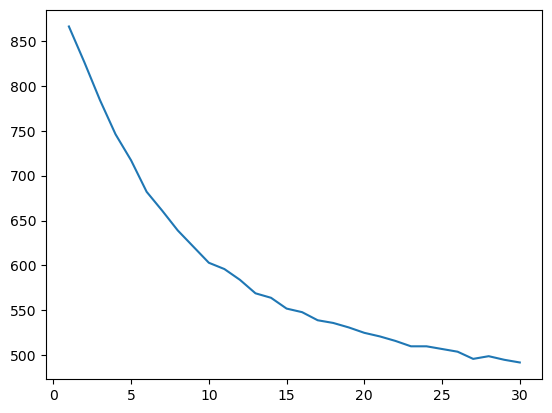

In [11]:
plt.plot(range(1,len(taus)+1),taus)

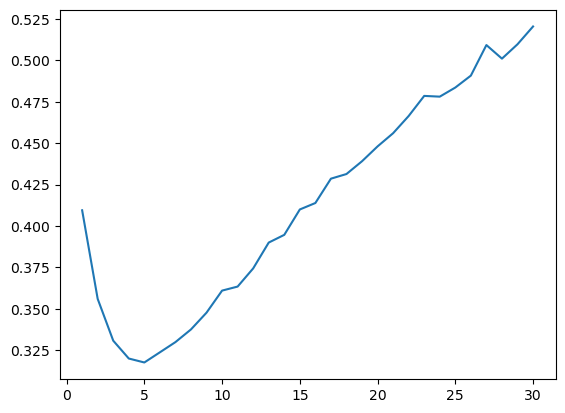

In [12]:
plt.plot(range(1,len(taus)+1),probs)

In [4]:
algos_dict = {
    #'IDS_logistic': [IDS_logistic, {'prob_threshold':.25}, 10, 'IDS_logistic', 'y'],
    'Greedy_logistic_freq': [Greedy_logistic_freq, {}, 10, 'Greedy_logistic_freq', 'y'],
    'Greedy_logistic': [G_logistic, {'prob_threshold':.35}, 100, 'Greedy_logistic', 'green'],
    #'TS_logistic': [TS_logistic, {'prob_threshold':.25}, 10, 'TS_logistic', 'red'],
    #'Greedy_logistic_2': [G_logistic, {'n_clus':50, 'ss_size':5, 'optimal_marg':.5}, 1, 'Greedy_logistic_2', 'green']
}

In [15]:
#res_G = defaultdict(list)

reg_list = {algo:[] for algo in algos_dict}
rwd_ev_list = {algo:[] for algo in algos_dict}
uncert_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
rwd_prop_list = {algo:[] for algo in algos_dict}
tau_list = {algo:[] for algo in algos_dict}
tau_true_list = {algo:[] for algo in algos_dict}
act_list = {algo:[] for algo in algos_dict}

sample_list = {var:[] for var in ['x', 'y', 'theta', 'true_tau']}

for trial_idx in trange(10):
    x, y, theta = gen_data(1000, p=10, scale=20)
    n_row, n_col = y.shape[0], 1
    _, n_desc =  x.shape
    cutoff = n_desc
    T = n_row
    prob_dict = {
                "m": n_row,
                "noise": 0.01,
                "d": cutoff
              }
    prob = logistic_discover(**prob_dict)
    #x = x - x.mean(0)
    #x = normalize(x, axis=0, norm='l2')
    prob.x = x.copy()
    prob.y = y.copy()
    #t_prob = deepcopy(prob)
    #solver = G_logistic(t_prob, prob_threshold=0.25) 
        #reg, act = solver.run(T, refresh=False)[:2]

        #actions_0 = [np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(10)]

    #reg, rwd, tau = solver.run(T)
    
    #res_G['true_tau'].append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    #res_G['reg'].append(reg)
    #res_G['tau'].append(tau)
    #res_G['rwd_prop'].append(np.array(rwd).sum()/y.sum())
    
    sample_list['x'].append(x)
    sample_list['y'].append(y)
    sample_list['true_tau'].append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    
    sample_list['theta'].append(theta)
    
    for algo, algo_setup in algos_dict.items():
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd, tau = solver.run(T, M=1, rho=0.1)#[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
        
        act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
        if np.isnan(tau):
            tau = T
        reg_list[algo].append(reg)
        rwd_list[algo].append(rwd)
        rwd_ev_list[algo].append(t_prob.rewards_ev)
        uncert_list[algo].append(t_prob.uncertainty)
        tau_true_list[algo].append(t_prob.tau_true)
        tau_list[algo].append(tau)
        rwd_prop_list[algo].append(np.array(rwd)[:tau].sum()/y.sum())
        

100%|███████████████████████████████████████████| 10/10 [02:39<00:00, 15.91s/it]


In [16]:
probs = [expit(x @ theta) for x, theta in zip(sample_list['x'], sample_list['theta'])]

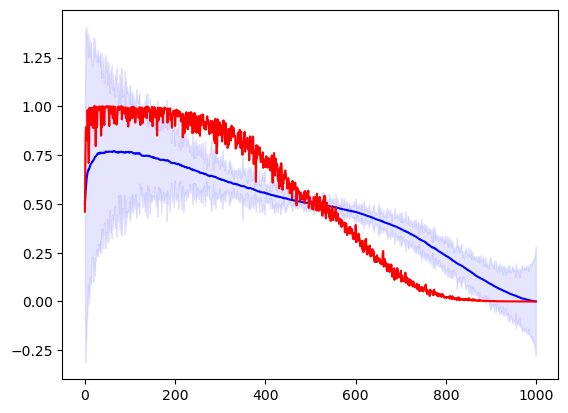

In [17]:
y_ = np.mean([rwd_ev_list['Greedy_logistic'][i] for i in range(10)], 0)
ci = np.mean([uncert_list['Greedy_logistic'][i] for i in range(10)], 0)

plt.plot(y_,c='b')
plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = 'b', alpha=.1)

#plt.plot(np.mean([rwd_ev_list['Greedy_logistic'][i] for i in range(10)], 0))
plt.plot(np.mean([probs[i][act_list['Greedy_logistic'][i]] for i in range(10)], 0), c='r')#.shape)

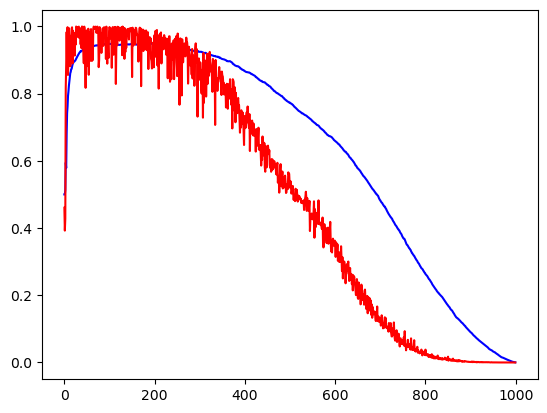

In [20]:
plt.plot(np.mean([rwd_ev_list['Greedy_logistic_freq'][i] for i in range(10)], 0), c='b')
plt.plot(np.mean([probs[i][act_list['Greedy_logistic_freq'][i]] for i in range(10)], 0), c='r')#.shape)

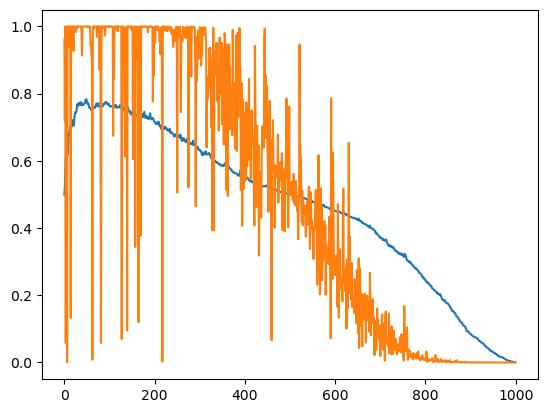

In [437]:
plt.plot(rwd_ev_list['Greedy_logistic'][0])
plt.plot(probs[0][act_list['Greedy_logistic'][0]])

In [389]:
np.sum(sample_list['y'], 1)[:,None].shape, np.cumsum(rwd_list['Greedy_logistic'],1).shape

((10, 1), (10, 1000))

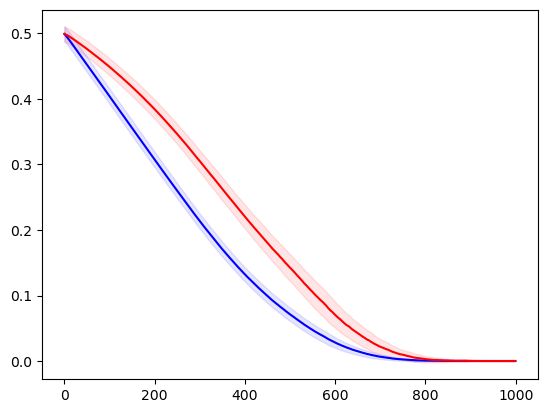

In [438]:
#ci = np.std(np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1), 0) / 100
#y_ = np.mean(np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1), 0) / 100

y_ = np.mean((np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1)) / 1000,0)
ci = np.std((np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1)) / 1000,0)

plt.plot(y_,c='b')
plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = 'b', alpha=.1)

#ci = np.std(np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1), 0) / (np.arange(100) + 1)[::-1]
#y_ = np.mean(np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1), 0) / (np.arange(100) + 1)[::-1]

y_ = np.mean((np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1)) / (np.arange(1000) + 1)[::-1],0)
ci = np.std((np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1)) / (np.arange(1000) + 1)[::-1],0)

plt.plot(y_,c='r')
plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = 'r', alpha=.1)




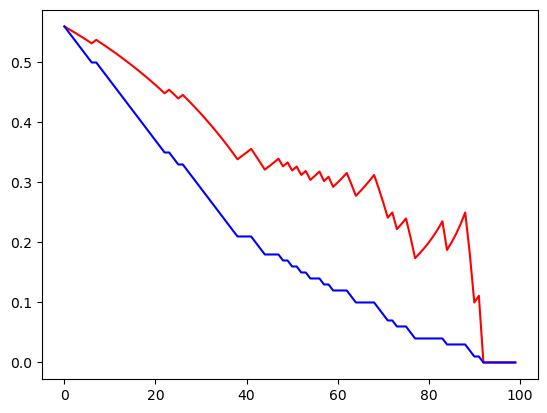

In [295]:
plt.plot((sum(solver.prob.y) - np.cumsum(solver.prob.y[np.array(solver.prob.actions)])) / (np.arange(100) + 1)[::-1],c='r')
plt.plot((sum(solver.prob.y) - np.cumsum(solver.prob.y[np.array(solver.prob.actions)])) / 100,c='b')

(array([ 1.,  4., 14., 21., 20., 24., 12.,  3.,  0.,  1.]),
 array([475. , 493.4, 511.8, 530.2, 548.6, 567. , 585.4, 603.8, 622.2,
        640.6, 659. ]),
 <BarContainer object of 10 artists>)

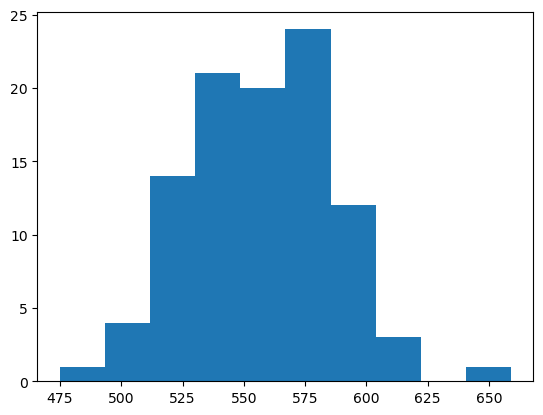

In [439]:
rwd_rem = (np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1)) / (np.arange(1000) + 1)[::-1]
plt.hist([np.where(np.cumsum(r<=.1) == 1)[0][0] for r in rwd_rem])

(array([10., 29., 36., 13.,  5.,  2.,  4.,  0.,  0.,  1.]),
 array([0.        , 0.00620438, 0.01240876, 0.01861314, 0.02481752,
        0.0310219 , 0.03722628, 0.04343066, 0.04963504, 0.05583942,
        0.0620438 ]),
 <BarContainer object of 10 artists>)

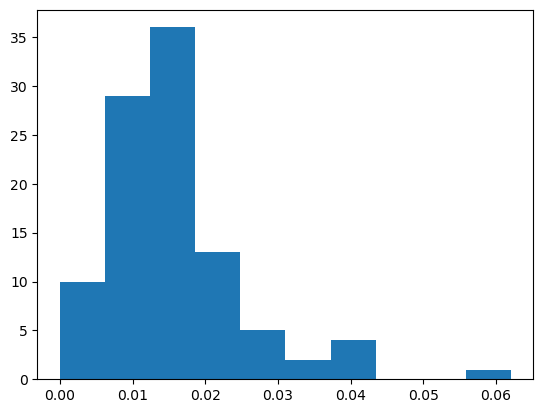

In [440]:
plt.hist([r[tau-1] for r,tau in zip(rwd_rem, tau_list['Greedy_logistic'])])

In [441]:
(np.mean([r[tau-1] < 0.1 for r,tau in zip(rwd_rem, tau_list['Greedy_logistic'])]),
np.quantile([r[tau-1] for r,tau in zip(rwd_rem, tau_list['Greedy_logistic'])], .9))

(1.0, 0.025664456455117855)

(array([ 3.,  4., 12., 23., 14., 19., 11.,  8.,  4.,  2.]),
 array([551. , 557.3, 563.6, 569.9, 576.2, 582.5, 588.8, 595.1, 601.4,
        607.7, 614. ]),
 <BarContainer object of 10 artists>)

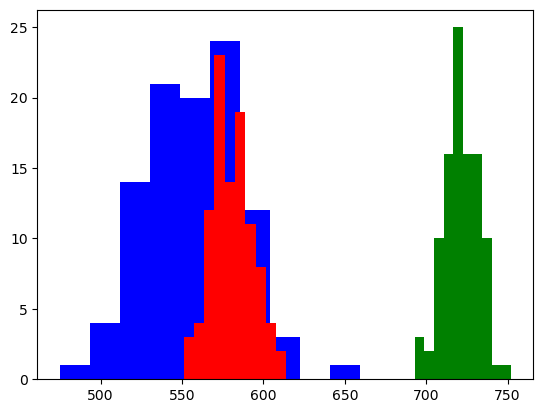

In [446]:
plt.hist(tau_true_list['Greedy_logistic'], color='b')
plt.hist(tau_list['Greedy_logistic'], color='g')

plt.hist([np.where((np.sort(p)[::-1] < 0.35).cumsum()==1)[0][0] for p in probs], color='r')

In [27]:
(np.mean(tau_true_list['Greedy_logistic']), 
 np.mean([np.where((np.sort(p)[::-1] < 0.35).cumsum()==1)[0][0] for p in probs]),
 np.mean(tau_list['Greedy_logistic']))

(565.0, 586.1, 721.3)

In [325]:
np.where(np.cumsum(np.mean([np.sort(p)[::-1] for p in probs], 0) < .35) == 1)[0][0]

61

In [343]:
(for zip([y[np.argsort(p)[::-1]].cumsum()/y.sum() for y, p in zip(sample_list['y'], probs)],
    [np.where((np.sort(p)[::-1] < 0.35).cumsum()==1)[0][0] for p in probs]))

[array([0.01818182, 0.03636364, 0.05454545, 0.07272727, 0.09090909,
        0.10909091, 0.10909091, 0.12727273, 0.14545455, 0.16363636,
        0.18181818, 0.2       , 0.21818182, 0.23636364, 0.25454545,
        0.27272727, 0.29090909, 0.30909091, 0.32727273, 0.34545455,
        0.36363636, 0.38181818, 0.4       , 0.41818182, 0.43636364,
        0.45454545, 0.45454545, 0.47272727, 0.47272727, 0.47272727,
        0.47272727, 0.47272727, 0.49090909, 0.50909091, 0.52727273,
        0.54545455, 0.56363636, 0.58181818, 0.58181818, 0.6       ,
        0.61818182, 0.63636364, 0.63636364, 0.65454545, 0.65454545,
        0.65454545, 0.65454545, 0.67272727, 0.67272727, 0.69090909,
        0.69090909, 0.69090909, 0.70909091, 0.70909091, 0.70909091,
        0.72727273, 0.74545455, 0.74545455, 0.76363636, 0.78181818,
        0.78181818, 0.78181818, 0.8       , 0.81818182, 0.81818182,
        0.83636364, 0.85454545, 0.87272727, 0.87272727, 0.89090909,
        0.89090909, 0.90909091, 0.90909091, 0.92

In [342]:
np.mean([np.where((np.sort(p)[::-1] < 0.35).cumsum()==1)[0][0] for p in probs])

62.67

(1.01, 0.0)

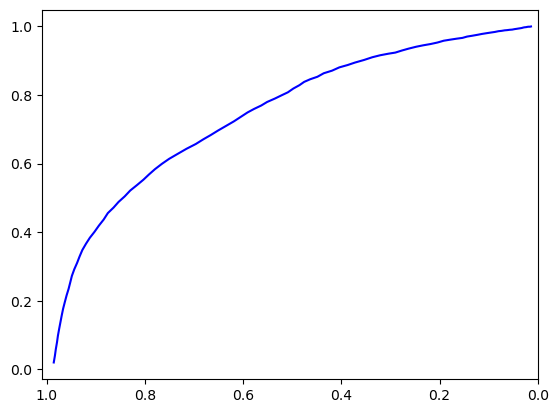

In [319]:
probs = [expit(x @ theta) for x, theta in zip(sample_list['x'], sample_list['theta'])]
y = [y for y in sample_list['y']]

plt.plot(np.mean([np.sort(p)[::-1] for p in probs], 0),
         np.mean([y[np.argsort(p)[::-1]].cumsum()/y.sum() for y, p in zip(sample_list['y'], probs)], 0), c='b')

plt.xlim(1.01,0)

(array([ 7., 24., 24., 18., 11.,  4.,  3.,  5.,  2.,  2.]),
 array([39. , 42.8, 46.6, 50.4, 54.2, 58. , 61.8, 65.6, 69.4, 73.2, 77. ]),
 <BarContainer object of 10 artists>)

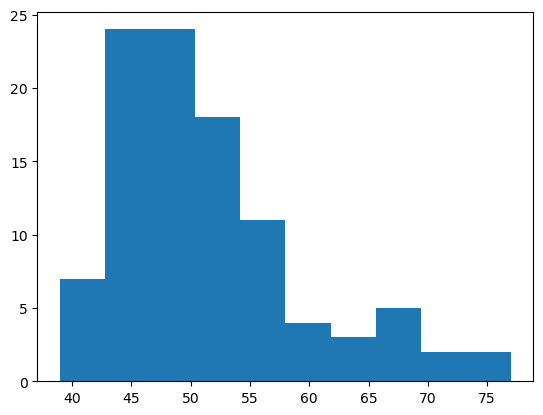

In [317]:
rwd_rem = (np.sum(sample_list['y'], 1)[:,None] - np.cumsum(rwd_list['Greedy_logistic'],1)) / 100
plt.hist([np.where(np.cumsum(r<0.1) == 1)[0][0] for r in rwd_rem])

# Include uncert in TS and IDS

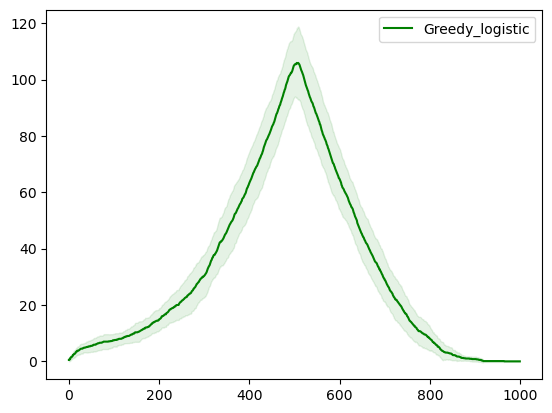

In [392]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [42]:
plt.plot(np.mean(reg_list['TS_logistic'], axis = 0) / np.mean(reg_list['Greedy_logistic'], axis = 0))

KeyError: 'TS_logistic'

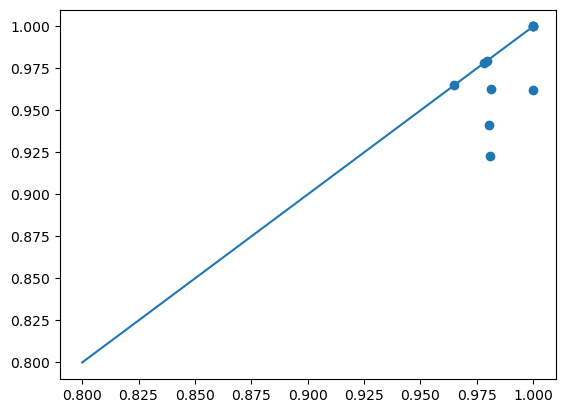

In [17]:
plt.scatter(
    rwd_prop_list['Greedy_logistic'],
    rwd_prop_list['TS_logistic']
)
plt.plot(np.linspace(.8,1),
        np.linspace(.8,1))

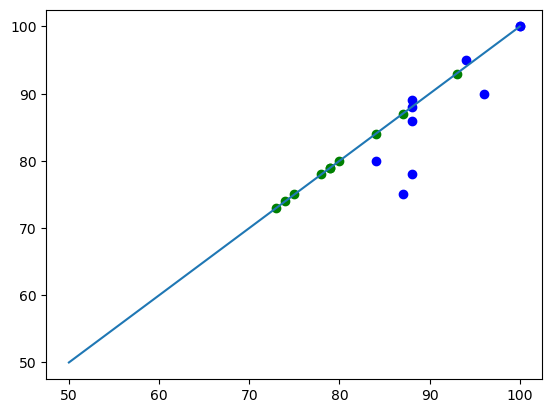

In [20]:
plt.scatter(tau_list['Greedy_logistic'],
            tau_list['TS_logistic'], c='b')

plt.plot(np.linspace(50,100),
        np.linspace(50,100))

plt.scatter(tau_true_list['Greedy_logistic'],
            tau_true_list['TS_logistic'], c='r')

plt.scatter(sample_list['true_tau'],
           sample_list['true_tau'], c='g')

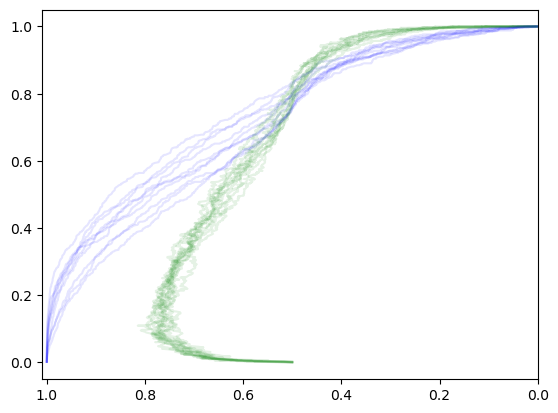

In [393]:
for i in range(10):
    probs = expit(sample_list['x'][i] @ sample_list['theta'][i])
    y = sample_list['y'][i]
    plt.plot(np.sort(probs)[::-1],
             y[np.argsort(probs)[::-1]].cumsum()/y.sum(),
             alpha=.1, c='b')

    plt.plot(rwd_ev_list['Greedy_logistic'][i],
             np.cumsum(rwd_list['Greedy_logistic'][i])/y.sum(), 
             alpha=.1, c='g', label='greedy')

    #plt.plot(rwd_ev_list['TS_logistic'][i],
    #         np.cumsum(rwd_list['TS_logistic'][i])/y.sum(), 
    #         alpha=.1, c='r', label='TS')
    plt.xlim(1.01,0)
#plt.legend()

(1.01, 0.0)

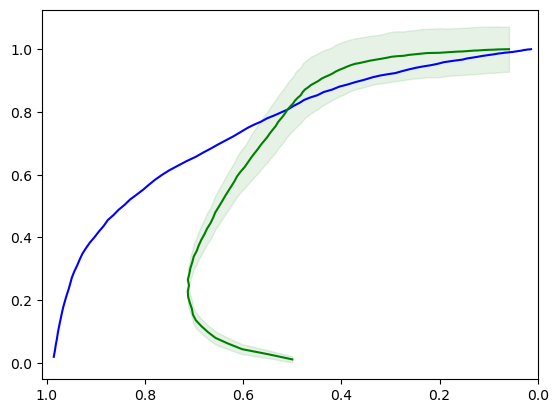

In [314]:
#probs = expit(sample_list['x'][i] @ sample_list['theta'][i])
#y = sample_list['y'][i]

#plt.plot(np.sort(probs)[::-1],
#             y[np.argsort(probs)[::-1]].cumsum()/y.sum(),
#             alpha=.1, c='b')
    
probs = [expit(x @ theta) for x, theta in zip(sample_list['x'], sample_list['theta'])]
y = [y for y in sample_list['y']]

plt.plot(np.mean([np.sort(p)[::-1] for p in probs], 0),
         np.mean([y[np.argsort(p)[::-1]].cumsum()/y.sum() for y, p in zip(sample_list['y'], probs)], 0), c='b')

plt.plot(np.mean(rwd_ev_list['TS_logistic'],0),
          np.mean(np.cumsum(rwd_list['TS_logistic'],1),0) / np.sum(sample_list['y'],1).mean(),
             alpha=1, c='r', label='TS')

z_ = np.mean(np.cumsum(rwd_list['TS_logistic'],1),0) / np.sum(sample_list['y'],1).mean()
di = np.std(np.cumsum(rwd_list['TS_logistic'],1),0) / np.sum(sample_list['y'],1).mean()

plt.fill_between(np.mean(rwd_ev_list['TS_logistic'],0).flatten(), (z_-di), (z_+di), color = 'r', alpha=.1)


plt.plot(np.mean(rwd_ev_list['Greedy_logistic'],0),
          np.mean(np.cumsum(rwd_list['Greedy_logistic'],1),0) / np.sum(sample_list['y'],1).mean(),
             alpha=1, c='g', label='greedy')

y_ = np.mean(np.cumsum(rwd_list['Greedy_logistic'],1),0) / np.sum(sample_list['y'],1).mean()
ci = np.std(np.cumsum(rwd_list['Greedy_logistic'],1),0) / np.sum(sample_list['y'],1).mean()

plt.fill_between(np.mean(rwd_ev_list['Greedy_logistic'],0), (y_-ci), (y_+ci), color = 'g', alpha=.1)

plt.xlim(1.01,0)

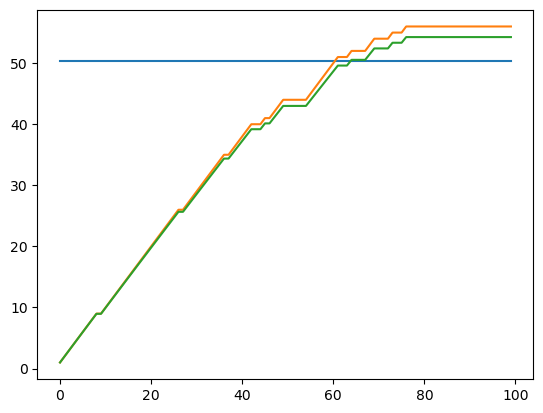

In [748]:
gamma = .999
disc = np.power(np.ones(100) * gamma, np.arange(100))

plt.plot(range(100), np.ones(100)*y[solver.prob.actions].sum()*.9)
plt.plot((y[solver.prob.actions]).cumsum())
plt.plot((y[solver.prob.actions] * disc).cumsum())

0.9043820750088044 76
0.9135172474836408 76
0.9227446944279201 76
0.9320653479069899 76
0.941480149401 76
0.9509900498999999 76
0.96059601 76
0.970299 76
0.9801 76
0.99 42


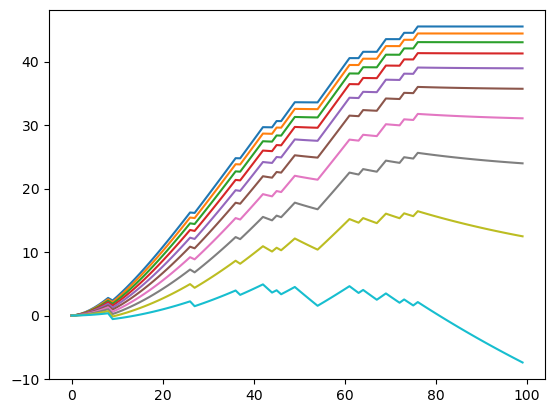

In [749]:
for gamma in np.logspace(10,1,base=.99, num=10): 
    disc = np.power(np.ones(100) * gamma, np.arange(100))
    print(gamma, np.argmax((y[solver.prob.actions]  - disc).cumsum()))
    plt.plot((y[solver.prob.actions]  - disc).cumsum())

In [766]:
ts = (np.argmax(np.clip((1.2*y[solver.prob.actions]-.2).cumsum(), 0,100)),
np.argmax(np.clip((1.5*y[solver.prob.actions]-.5).cumsum(), 0,100)),
np.argmax(np.clip((2*y[solver.prob.actions]-1).cumsum(), 0,100)),
np.argmax(np.clip((3*y[solver.prob.actions]-2).cumsum(), 0,100)),
np.argmax(np.clip((4*y[solver.prob.actions]-3).cumsum(), 0,100)),
np.argmax(np.clip((10*y[solver.prob.actions]-9).cumsum(), 0,100)))
ts

(76, 69, 61, 42, 42, 26)

In [765]:
[np.sum(y[solver.prob.actions[:t]])/np.sum(y[solver.prob.actions]) for t in ts]

[0.9821428571428571,
 0.9464285714285714,
 0.8928571428571429,
 0.6964285714285714,
 0.6964285714285714,
 0.44642857142857145]

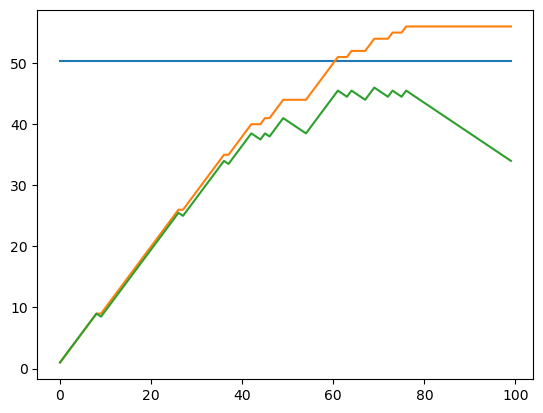

In [767]:
plt.plot(range(100), np.ones(100)*y[solver.prob.actions].sum()*.9)
plt.plot((y[solver.prob.actions]).cumsum())
#plt.plot(np.clip((1.2*y[solver.prob.actions]-.2).cumsum(), 0,100))
plt.plot(np.clip((1.5*y[solver.prob.actions]-.5).cumsum(), 0,100))
#plt.plot(np.clip((2*y[solver.prob.actions]-1).cumsum(), 0,100))
#plt.plot(np.clip((3*y[solver.prob.actions]-2).cumsum(), 0,100))
#plt.plot(np.clip((4*y[solver.prob.actions]-3).cumsum(), 0,100))

#plt.plot(np.clip((10*y[solver.prob.actions]-9).cumsum(), 0,100))

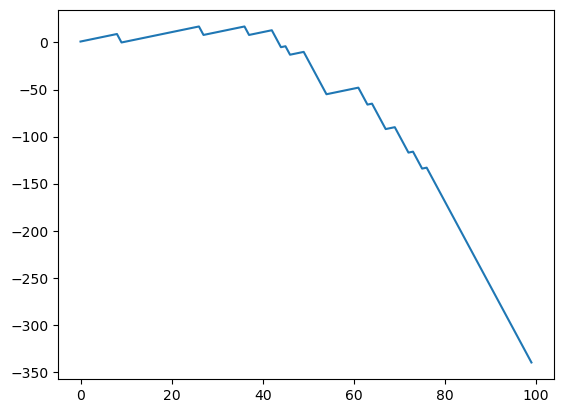

In [754]:
plt.plot((10*y[solver.prob.actions]-9).cumsum())
#plt.ylim(0,400)